In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_kddcup99
import pandas as pd

SEED = 2024054
np.random.seed(SEED)

In [2]:
#data loading
kdd = fetch_kddcup99(subset=None, as_frame=True)
X = kdd.data.copy()
cat = ['protocol_type', 'service', 'flag']
for c in cat:
    X[c] = X[c].apply(lambda x: x.decode() if isinstance(x, bytes) else x)

num = [c for c in X.columns if c not in cat]
X[num] = X[num].astype(float) #convert numerical features to float

X = pd.get_dummies(X, columns=cat, dtype=float) #one hot encoding cat features
X = X.loc[:, X.nunique() > 1] #remove columns with constant values
D = X.to_numpy(dtype=float) #convert dataframe into matrix D

#normalizing
mn = D.min(axis=0) #column min
mx = D.max(axis=0) #column max
D = (D - mn) / (mx - mn) #scaling each column between 0 and 1

y = (kdd.target != b'normal.').to_numpy(dtype=float) #y = 0 if normal; 1 if attack

n, d = D.shape #number of rows and columns
print("n =", n, "d =", d)
print("rank of D =", np.linalg.matrix_rank(D)) #calculate rank of D

#a
start = time.perf_counter() #start timer
b = np.linalg.lstsq(D, y, rcond=None)[0] #find full least squares solution
end_time = time.perf_counter() - start #calculate execution time
total_L = np.sum((D @ b - y)**2) #calculate full regression loss

print("\nQ2(a)")
print("Total loss:", total_L)
print("Total time:", end_time)

n = 494021 d = 116
rank of D = 113

Q2(a)
Total loss: 2949.7888440371603
Total time: 6.404704928000001


In [3]:
#b
def countsketch(D, y, m, rng):
    n = D.shape[0]
    h = rng.integers(0, m, size=n) #assigning every row to a random bucket
    s = rng.choice([-1, 1], size=n) #assigning random signs to every row

    SD = np.zeros((m, D.shape[1])) #create empty sketched data matrix
    Sy = np.zeros(m) #create empty sketched target vector

    np.add.at(SD, h, s[:, None] * D) #add signed rows of D to their buckets
    np.add.at(Sy, h, s * y) #add signed values of y to their buckets

    return SD, Sy #return sketched matrix and target vector



Q2(b) and Q2(c)
m | Mean original loss | Mean ratio | Min ratio | Max ratio | Mean sketch loss | Mean time
50 10589.659375861123 3.5899720067311094 2.7038074999559925 4.77602099033997 1.7054805950557347e-23 2.127833749800004
100 56269.97969324669 19.07593481038259 10.635427720304023 36.412357667323754 1.946034040890966e-23 2.259976266600006
200 6547.9707849094575 2.219810003738345 1.9026631669489513 2.5223809092526235 1262.971765143852 2.14407262499999
500 3873.4465792193846 1.3131267300875955 1.251444561090315 1.3615437691976677 2301.2004473827556 2.1651892329999667
1000 3310.96795698495 1.1224423618246078 1.1135835951315811 1.1367811865441253 2657.7575640517052 2.2122736454000234
2000 3135.3032040245266 1.0628907253352637 1.047031823334319 1.0832944065342747 2820.3033135557994 2.2441491165999876
5000 3016.222934346974 1.0225216426742227 1.0202817459613507 1.0260131647729942 2913.778070014544 2.3801690342000486


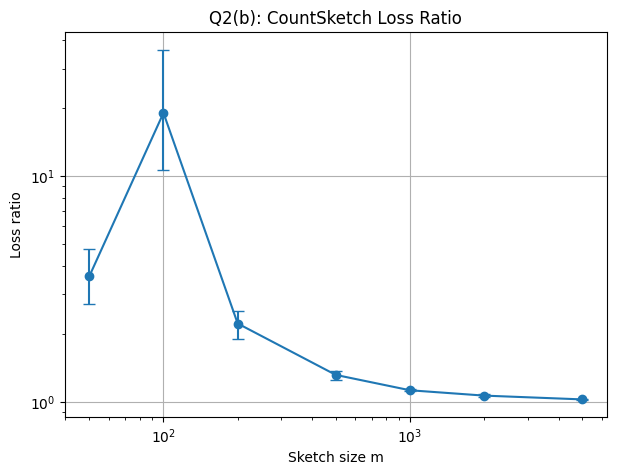

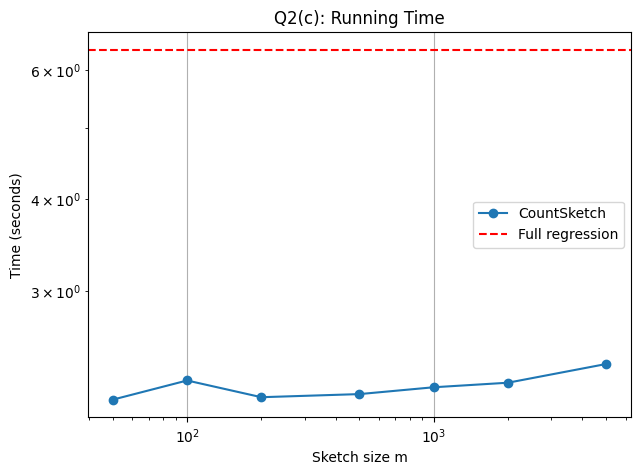

In [4]:
#c
ms = [50, 100, 200, 500, 1000, 2000, 5000] #different sketch sizes
R = 5 #number of repetitions for each sketch size

ratios = {} #store loss ratios
times = {} #store execution times
sketched_losses = {} #store sketched losses

for m in ms:
    ratios[m] = []
    times[m] = []
    sketched_losses[m] = []

    for r in range(R):
        rng = np.random.default_rng([SEED, m, r]) #generate fixed random seed
        start = time.perf_counter() #start timer

        SD, Sy = countsketch(D, y, m, rng) #create CountSketch
        a = np.linalg.lstsq(SD, Sy, rcond=None)[0] #solve sketched least squares

        elapsed = time.perf_counter() - start #calculate sketching and solving time

        original_loss = np.sum((D @ a - y)**2) #calculate loss on original data
        sketch_loss = np.sum((SD @ a - Sy)**2) #calculate loss on sketched data

        ratios[m].append(original_loss / total_L) #calculate loss ratio
        sketched_losses[m].append(sketch_loss) #store sketched loss
        times[m].append(elapsed) #store execution time


#calculate mean, minimum and maximum ratios for each m
print("\nQ2(b) and Q2(c)")
print("m | Mean original loss | Mean ratio | Min ratio | Max ratio | Mean sketch loss | Mean time")

for m in ms:
    print(
        m,
        np.mean(ratios[m]) * total_L,#mean original loss
        np.mean(ratios[m]), #mean loss ratio
        np.min(ratios[m]), #minimum ratio
        np.max(ratios[m]),    #maximum ratio
        np.mean(sketched_losses[m]), #mean sketched loss
        np.mean(times[m])   #mean execution time
    )

#plot mean loss ratios with minimum and maximum error bars
means = [np.mean(ratios[m]) for m in ms]
mins = [np.min(ratios[m]) for m in ms]
maxs = [np.max(ratios[m]) for m in ms]

plt.figure(figsize=(7, 5))
plt.errorbar(
    ms, means,
    yerr=[np.array(means)-mins, np.array(maxs)-means],
    fmt='o-', capsize=4
)

plt.xscale('log') #log scale for x-axis
plt.yscale('log') #log scale for y-axis
plt.xlabel('Sketch size m')
plt.ylabel('Loss ratio')
plt.title('Q2(b): CountSketch Loss Ratio')
plt.grid()
plt.savefig('q2b.png') #save plot
plt.show()


#plot average execution time against sketch size
plt.figure(figsize=(7, 5))
plt.plot(ms, [np.mean(times[m]) for m in ms], 'o-', label='CountSketch')
plt.axhline(end_time, color='red', linestyle='--', label='Full regression') #full regression time

plt.xscale('log')
plt.yscale('log')
plt.xlabel('Sketch size m')
plt.ylabel('Time (seconds)')
plt.title('Q2(c): Running Time')
plt.legend()
plt.grid()
plt.savefig('q2c.png') #save plot
plt.show()



Q2(d)
m = 50 Mean = 0.9625789198787011 Std = 0.18533641831584835
m = 500 Mean = 0.9812323732390873 Std = 0.05771144197568237
m = 5000 Mean = 1.0008497396564584 Std = 0.02058120388089208


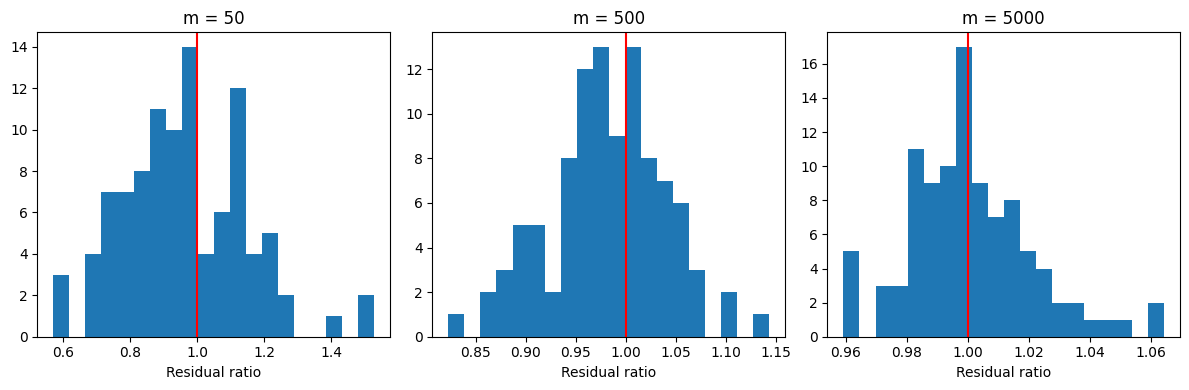

In [5]:
#d
v = D @ b - y #calculate residual of full regression solution
v2 = np.sum(v**2) #calculate squared norm of residual

print("\nQ2(d)")

plt.figure(figsize=(12, 4))

for j, m in enumerate([50, 500, 5000]):
    values = []

    for r in range(100):
        rng = np.random.default_rng([SEED, 999, m, r]) #generate fixed random seed

        h = rng.integers(0, m, size=n) #assign residuals to random buckets
        s = rng.choice([-1, 1], size=n) #generate random signs

        Sv = np.bincount(h, weights=s * v, minlength=m) #calculate sketched residual
        values.append(np.sum(Sv**2) / v2) #calculate residual norm ratio

    values = np.array(values)

    #calculate mean and standard deviation
    print(
        "m =", m,
        "Mean =", np.mean(values),
        "Std =", np.std(values, ddof=1)
    )

    plt.subplot(1, 3, j+1)
    plt.hist(values, bins=20) #plot histogram
    plt.axvline(1, color='red') #reference line at 1
    plt.title("m = " + str(m))
    plt.xlabel("Residual ratio")

plt.tight_layout()
plt.savefig('q2d.png') #save histogram plots
plt.show()

In [6]:
#e
rng = np.random.default_rng(SEED + 1)
sub = rng.choice(n, size=min(50000, n), replace=False) #select 50000 random rows without replacement

Dp = D[sub] #selected rows of D
yp = y[sub] #matching target values

bp = np.linalg.lstsq(Dp, yp, rcond=None)[0] #solve least squares on subset
L_subset = np.sum((Dp @ bp - yp)**2) #calculate subset regression loss

m = 500 #sketch size

count_times = [] #store CountSketch times
count_ratios = [] #store CountSketch loss ratios

gauss_times = [] #store Gaussian sketch times
gauss_ratios = [] #store Gaussian sketch loss ratios

for r in range(5):

    #CountSketch
    rng = np.random.default_rng([SEED, 5000, r])
    start = time.perf_counter() #start timer

    SD, Sy = countsketch(Dp, yp, m, rng) #create CountSketch
    count_time = time.perf_counter() - start #calculate sketching time

    a = np.linalg.lstsq(SD, Sy, rcond=None)[0] #solve sketched least squares

    count_times.append(count_time)
    count_ratios.append(np.sum((Dp @ a - yp)**2) / L_subset) #calculate loss ratio


    #Gaussian sketch
    rng = np.random.default_rng([SEED, 6000, r])
    start = time.perf_counter() #start timer

    S = rng.normal(0, 1/np.sqrt(m), size=(m, len(sub))) #generate Gaussian random matrix
    SD = S @ Dp #form sketched data matrix
    Sy = S @ yp #form sketched target vector

    gauss_time = time.perf_counter() - start #calculate sketching time

    a = np.linalg.lstsq(SD, Sy, rcond=None)[0] #solve sketched least squares

    gauss_times.append(gauss_time)
    gauss_ratios.append(np.sum((Dp @ a - yp)**2) / L_subset) #calculate loss ratio


#compare average times and loss ratios
print("\nQ2(e)")

print("CountSketch:")
print("Mean time:", np.mean(count_times))
print("Mean loss ratio:", np.mean(count_ratios))

print("Gaussian Sketch:")
print("Mean time:", np.mean(gauss_times))
print("Mean loss ratio:", np.mean(gauss_ratios))


Q2(e)
CountSketch:
Mean time: 0.1782270454000127
Mean loss ratio: 1.316372162006157
Gaussian Sketch:
Mean time: 0.73025661879999
Mean loss ratio: 1.2769110875804024
